# IEEE 13-bus ERCOT sequential DDPG training and hourly reference comparison

## Purpose

This notebook trains, evaluates, or views sequential DDPG runs against neutral taps and native RegControl. Each evaluation follows complete days with persistent tap positions. Results describe this saved ERCOT validation split and measured daily shapes; they do not establish convergence or general performance.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().parents[1]
if not (ROOT / "src/feeder").is_dir():
    raise RuntimeError("Start the kernel in the notebook directory (experiments/<feeder>/).")
sys.path.insert(0, str(ROOT / "src"))

from common.reports import show_conclusions, show_controller_comparison, show_day, show_paired_counts, show_training_summary
from common.workflow import run_experiment

print("Repository root resolved.")

Repository root resolved.


## Parameters

Edit this cell, then restart the kernel and run all cells. `MODE` selects `train`, `evaluate`, or read-only `view`; `OVERWRITE` affects only writing modes. The former `TRAIN = True` maps to `MODE = "train"`, while `TRAIN = False` with evaluation maps to `MODE = "evaluate"`; use `view` for saved results.

In [2]:
FEEDER = "ieee13"  # Named feeder.
DATASET = "ieee13-ercot"  # Named dataset.
SEEDS = [0, 1, 2]  # Independent training seeds.
MODE = "view"  # train, evaluate, or read saved results.
OVERWRITE = False  # Applies only to train and evaluate.
SHOW_HOURLY_DETAILS = False  # Display the selected day's detailed rows.
TRAINING_DAYS = 7985  # Training only: complete days per run.
REWARD = "band"  # Training only: reward name.
BETA = 1e-5  # Benchmark switching-cost weight per tap step.
REWARD_PARAMETERS = {"beta": BETA}  # Training only: overrides of the reward defaults.
SPLIT = "validation"  # Evaluation split.
EVALUATION_DAYS = None  # Complete split or a positive day limit.
RUN_NAME = "band_b1e-05"  # Run directory name before _seed<seed>.
PLOT_DAY = 280  # Selected evaluated day by zero-based position.

**Units and interfaces.** Solver voltages and executed tap ratios use physical p.u. values; tap positions are integer grid indices. Combined cost adds voltage excursion outside [0.95, 1.05] p.u. and `BETA` times executed tap steps. The recorded reward and benchmark remain distinct saved settings.

In [3]:
results = run_experiment({
    "protocol": "sequential",
    "algorithm": "ddpg",
    "feeder": FEEDER,
    "dataset": DATASET,
    "seeds": SEEDS,
    "mode": MODE,
    "overwrite": OVERWRITE,
    "training_days": TRAINING_DAYS,
    "reward": REWARD,
    "reward_parameters": REWARD_PARAMETERS,
    "beta": BETA,
    "split": SPLIT,
    "evaluation_days": EVALUATION_DAYS,
    "run_name": RUN_NAME,
    "plot_day": PLOT_DAY,
    "show_hourly_details": SHOW_HOURLY_DETAILS,
    "root": ROOT,
})

Dataset: ieee13-ercot (data/scenarios/ieee13-ercot)
Split: validation
Evaluated: 636 days, 15264 hours
Seeds: [0, 1, 2]
Training days per seed: recorded in saved training records
Switching-cost weight beta: 1e-05
Reward: band {'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.0, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}
Display names and run directories:
  DDPG seed 0: results/ieee13-ercot/seq_ddpg/band_b1e-05_seed0/
  DDPG seed 1: results/ieee13-ercot/seq_ddpg/band_b1e-05_seed1/
  DDPG seed 2: results/ieee13-ercot/seq_ddpg/band_b1e-05_seed2/
  Neutral: results/ieee13-ercot/seq_reference/neutral_b1e-05/
  RegControl: results/ieee13-ercot/seq_reference/regcontrol_b1e-05/
Mode: view
Overwrite: False
Preflight passed. No subprocess has started before this point.
Using existing saved results. View mode launches no subprocess.


Day and hour alignment passed for 636 days, 15264 hours, and 5 methods.


## Training records

An episode is one complete 24-decision day. “Training combined cost per day” shows the smoothed seed mean of the fixed evaluation cost on training episodes.

Training includes exploration; these curves are not held-out performance or proof of convergence.

Run,Reward,Reward parameters,Benchmark beta,Layer sizes,Completed training days,Update counts
DDPG seed 0,band,"{'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.0, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",1e-05,"[400, 300]",7985,unavailable
DDPG seed 1,band,"{'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.0, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",1e-05,"[400, 300]",7985,unavailable
DDPG seed 2,band,"{'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.0, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",1e-05,"[400, 300]",7985,unavailable


band_b1e-05_seed0: 7985 completed episodes, 191640 environment interactions
band_b1e-05_seed1: 7985 completed episodes, 191640 environment interactions
band_b1e-05_seed2: 7985 completed episodes, 191640 environment interactions


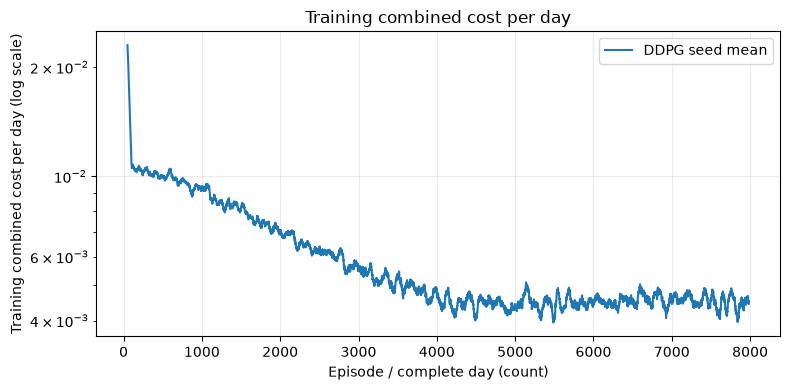

Cost uses the fixed evaluation metric on training episodes and includes exploration. It is not held-out performance or proof of convergence.

In [4]:
show_training_summary(results);


## Overall comparison

Daily voltage cost sums 24 hourly costs. Tap steps sum absolute executed position changes, including the first movement from neutral; switching cost is `BETA` times those steps. Feasible hours require convergence and every monitored voltage inside the band. Across-seed spread describes runs, not days or confidence intervals.

In [5]:
show_controller_comparison(results);


Neutral holds every regulator ratio at 1.0. RegControl uses the feeder's native regulator control.

Hourly voltage cost is the mean squared excursion outside [0.95, 1.05] p.u. over 41 monitored line-ground voltage measurements; in-band measurements contribute zero. Daily voltage cost sums 24 hourly costs, and the table averages these daily totals across evaluation days. Lower cost is better. Beta weights tap movement; it is not a monetary price.

Method,Mean daily combined cost,Mean daily voltage cost,Mean daily switching cost,Mean absolute deviation (p.u.),Mean tap steps/day,Feasible hours (%),Days
DDPG seed 0,6.78728e-05,3.72124e-05,3.06604e-05,2.0487e-02,3.066,64.7,636
DDPG seed 1,8.14984e-05,5.33695e-05,2.81289e-05,2.1112e-02,2.813,61.8,636
DDPG seed 2,5.42309e-05,2.15579e-05,3.26730e-05,2.0500e-02,3.267,65.5,636
Neutral,7.49495e-04,7.49495e-04,0.00000e+00,2.3465e-02,0.000,55.4,636
RegControl,1.87381e-04,1.61018e-06,1.85770e-04,1.3235e-02,18.577,96.0,636


DDPG statistic,Mean daily combined cost,Mean daily voltage cost,Mean daily switching cost,Mean absolute deviation (p.u.),Mean tap steps/day,Feasible hours (%)
Across-seed mean,6.78674e-05,3.73799e-05,3.04874e-05,2.0700e-02,3.049,64.0
Sample standard deviation,1.36338e-05,1.59065e-05,2.27694e-06,3.5744e-04,0.228,2.0


### Paired daily counts

Counts compare exact saved combined costs on matched days. Equality is exact, not a practical-equivalence test, and counts do not show improvement size.

In [6]:
show_paired_counts(results)

DDPG run,Reference,Lower-cost days,Equal-cost days,Higher-cost days
DDPG seed 0,Neutral,350,257,29
DDPG seed 0,RegControl,635,0,1
DDPG seed 1,Neutral,373,259,4
DDPG seed 1,RegControl,623,0,13
DDPG seed 2,Neutral,376,245,15
DDPG seed 2,RegControl,636,0,0


## Selected-day behavior

The selected day follows measured ERCOT hourly loads, normalised by the calendar-year peak. Executed ratios span 0.90 to 1.10; changing `PLOT_DAY` or the detail switch only changes this display.

Selected day: 2024-10-08


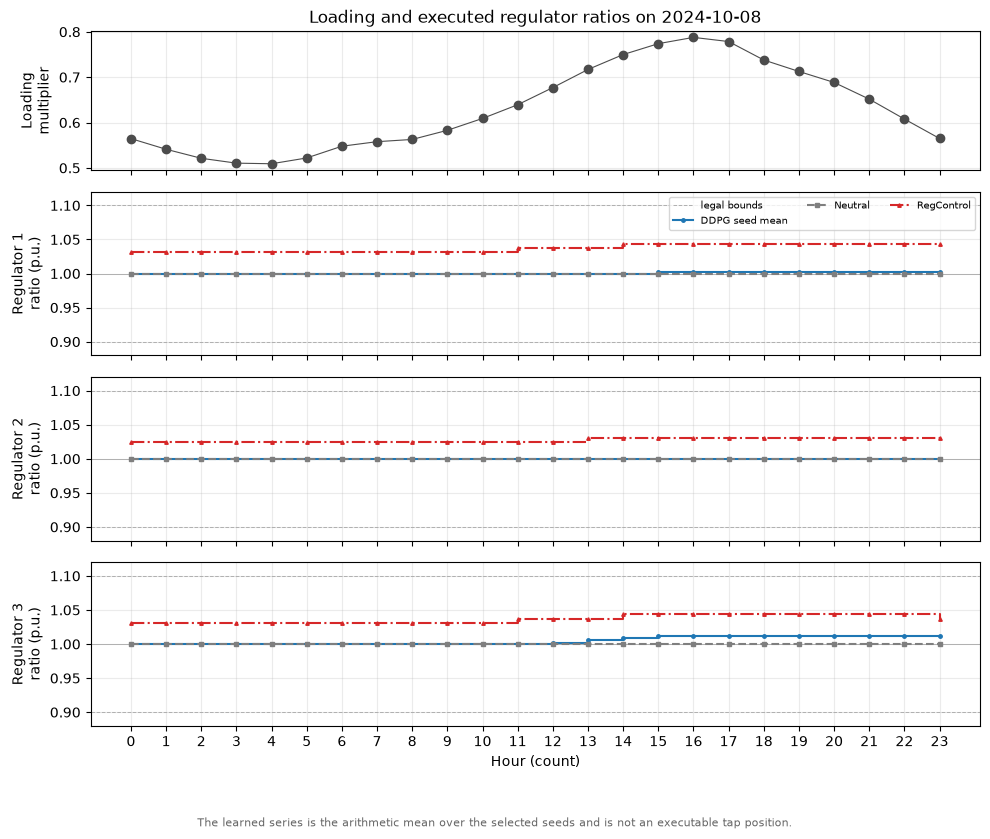

The learned series is the arithmetic mean over the selected seeds and is not an executable tap position.

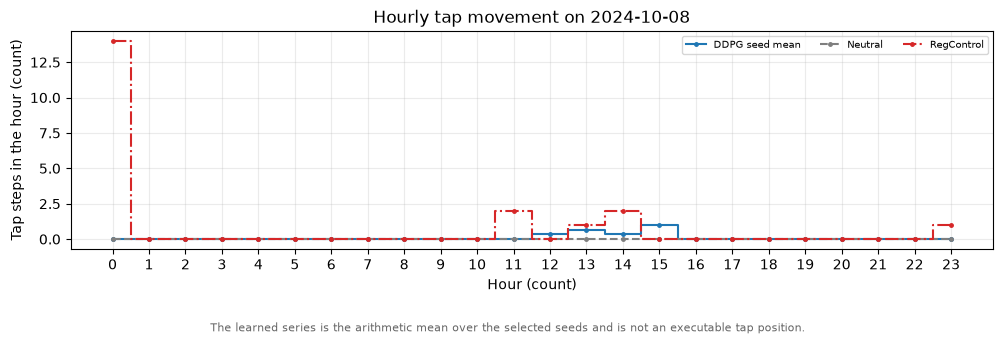

The learned series is the arithmetic mean over the selected seeds and is not an executable tap position.

Switching cost is tap steps times beta (1e-05).

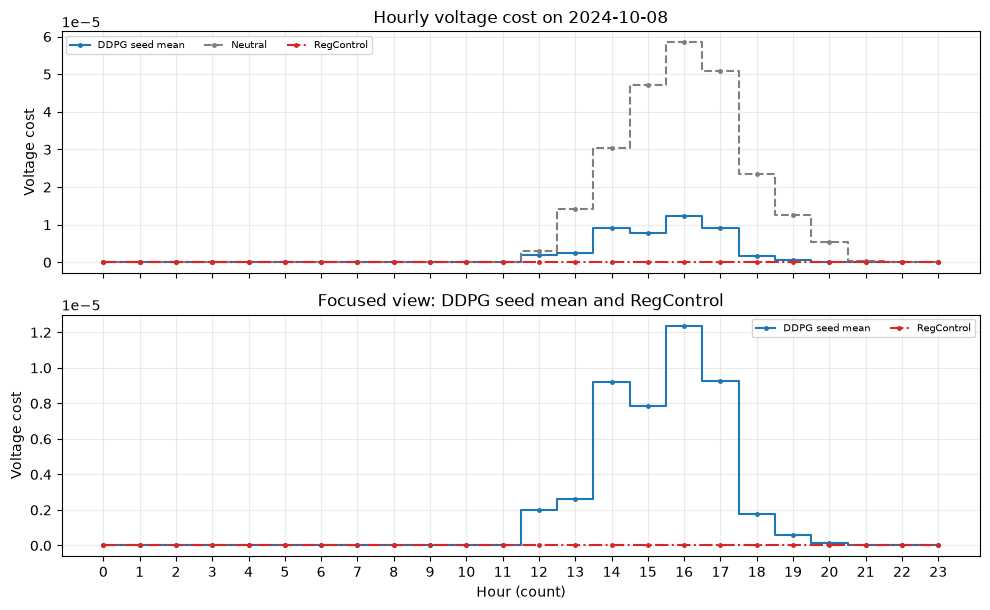

The upper panel keeps every method. The lower panel repeats the controller series without Neutral so their smaller differences remain readable.

Hourly detail table hidden. Set SHOW_HOURLY_DETAILS = True to display it.


In [7]:
show_day(results, PLOT_DAY, SHOW_HOURLY_DETAILS);


## Conclusions

In [8]:
show_conclusions(results)

The validation evaluation covers 636 days for 3 DDPG seeds, beta 1e-05, and 7985 complete training days per seed.

Across 3 independent seeds, DDPG mean daily combined cost is 6.78674e-05 with sample standard deviation 1.36338e-05. This is lower than Neutral (7.49495e-04) and lower than RegControl (1.87381e-04).

DDPG averages voltage cost 3.73799e-05, mean absolute deviation 2.0700e-02 p.u., 3.049 tap steps/day, and 64.0% feasible hours. Neutral uses 0.000 steps/day with voltage cost 7.49495e-04, mean absolute deviation 2.3465e-02 p.u., and 55.4% feasible hours; RegControl uses 18.577 steps/day with voltage cost 1.61018e-06, mean absolute deviation 1.3235e-02 p.u., and 96.0% feasible hours.

Against RegControl, DDPG's voltage cost is higher than RegControl's, its tap steps are lower than RegControl's, and its feasible hours are lower than RegControl's.

These results are limited to the validation split, these dataset inputs, and the recorded training budget.